# 03 · Do evento ao OEE, e como migrar sem regravar as placas

**Objetivo:** passar um turno de três máquinas pelo coletor de referência, calcular o OEE e conferir contra o que realmente aconteceu. Depois, trazer os firmwares v0 para o contrato com um adaptador.

## Antes de começar

- **Você precisa de:** os notebooks 01 e 02.
- **Tempo:** 25 minutos.
- **Broker:** nenhum.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
%matplotlib inline

## 1. O turno e a verdade

`oeelab.scenario` gera um turno de 8 horas para três máquinas, sempre igual (a semente é fixa). Cada máquina roda, para algumas vezes, faz cerca de 3 % de refugo e **perde a rede uma vez**.

O roteiro também devolve a **verdade**: quantas peças foram realmente feitas e quanto tempo a máquina realmente rodou. É contra isso que o coletor será conferido.

In [2]:
from oeelab.scenario import MACHINES, script

for nome in MACHINES:
    passos, verdade = script(nome)
    print(f"{nome:10s} {len(passos):6d} passos | boas {verdade.good:6d} | refugo {verdade.defect:4d} | "
          f"rodando {verdade.run_s/3600:4.2f} h | rede fora {verdade.offline_s/60:3.1f} min | paradas {len(verdade.stops)}")

filler-01   11406 passos | boas  11060 | refugo  326 | rodando 7.44 h | rede fora 4.6 min | paradas 8
capper-01   11340 passos | boas  10968 | refugo  350 | rodando 7.38 h | rede fora 4.9 min | paradas 9
press-02     3563 passos | boas   3435 | refugo  108 | rodando 6.93 h | rede fora 3.3 min | paradas 9


## 2. O coletor

`Collector.handle()` recebe tópico, bytes e hora de recebimento, e grava em SQLite. A ordem das decisões é a da seção 5 do contrato:

1. tópico ou payload fora do contrato vai para a tabela de recusados, com o motivo;
2. `status` atualiza a saúde do nó;
3. mesmo `boot` com `seq` já visto é repetição;
4. salto no `seq` é registrado como perda;
5. contador soma a diferença de `total`.

### Pare e preveja

O turno vai passar pelo coletor duas vezes: uma com nós v1 e outra com nós v0 (contados pela regra do notebook 02). As máquinas fazem menos de uma peça por segundo e o relógio está certo. O v0 erra a contagem? Onde?

In [3]:
from oeelab.lab import run_shift, counted

v1, v0 = run_shift("v1"), run_shift("v0")
print(f"{'máquina':10s} {'verdade':>8s} {'v1':>8s} {'v0':>8s} {'v0 perdeu':>10s}")
for nome, (maquina, _) in MACHINES.items():
    verdade = v1[nome][1].good
    c1, c0 = counted(v1[nome][0], maquina), counted(v0[nome][0], maquina)
    print(f"{nome:10s} {verdade:8d} {c1:8d} {c0:8d} {verdade - c0:10d}")

máquina     verdade       v1       v0  v0 perdeu
filler-01     11060    11060    10947        113
capper-01     10968    10968    10851        117
press-02       3435     3435     3408         27


O v0 perde exatamente as peças feitas enquanto a rede estava fora. É pouco mais de 1 % da produção em cada máquina, com uma única queda de poucos minutos no turno. Uma planta com Wi-Fi instável perde isso várias vezes por dia, sempre para o mesmo lado: **contando menos**.

## 3. Do que foi gravado ao OEE

Com estados e contagens gravados, o OEE é aritmética:

- **Disponibilidade** = tempo rodando ÷ tempo planejado
- **Performance** = (peças × ciclo ideal) ÷ tempo rodando
- **Qualidade** = peças boas ÷ peças totais

máquina      disp.   perf.   qual.     OEE   tempo rodando (coletor / verdade)
filler-01    93.0%   85.0%   97.1%   76.8%     26788 s /   26788 s
capper-01    92.2%   85.2%   96.9%   76.2%     26561 s /   26561 s
press-02     86.6%   85.2%   97.0%   71.6%     24943 s /   24943 s


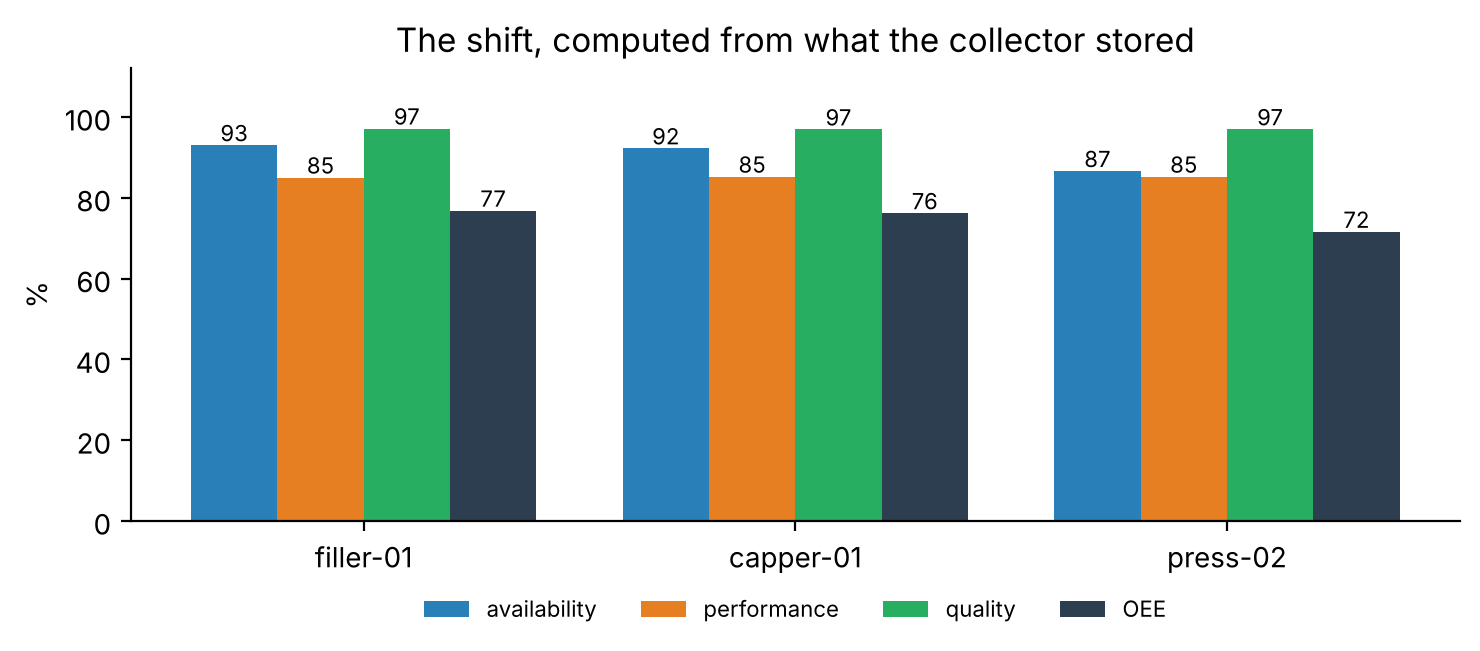

In [4]:
from datetime import timedelta
from oeelab.oee import compute
from oeelab.scenario import SHIFT_START, SHIFT_HOURS

fim = SHIFT_START + timedelta(hours=SHIFT_HOURS)
print(f"{'máquina':10s} {'disp.':>7s} {'perf.':>7s} {'qual.':>7s} {'OEE':>7s}   tempo rodando (coletor / verdade)")
for nome, (maquina, ciclo) in MACHINES.items():
    rx, verdade = v1[nome]
    o = compute(rx, maquina.base, SHIFT_START, fim, ciclo)
    print(f"{nome:10s} {o.availability:7.1%} {o.performance:7.1%} {o.quality:7.1%} {o.oee:7.1%}   {o.run_s:7.0f} s / {verdade.run_s:7.0f} s")
figures = __import__("oeelab.figures", fromlist=["oee"]); figures.oee();

O tempo rodando sai do sinal `state`, que é retido e republicado a cada reconexão. Os eventos `start` e `stop` registram a intenção do operador e podem se perder sem estragar a conta.

O mesmo turno, enviado no contrato v1 para um painel de OEE de verdade:

![Painel](../docs/img/dashboard_multi.png)

## 4. O que o coletor recusa

Um contrato só vale se alguém o faz cumprir. Vamos mandar ao coletor o que os firmwares v0 publicam hoje:

In [5]:
from oeelab.collector import Collector
from oeelab.contract import Machine

c = Collector()
m = Machine("packaging", "line-1", "cell-a", "filler-01")
agora = SHIFT_START
print(c.handle(m.topic("output-good"), b'{"ts":"2026-11-10T06:00:00","value":1,"machine_id":"FILLER-01"}', agora))
print(c.handle("fabrica/linha1/m1/input/3", b'{"label":"Peca boa","state":1,"ts":123456}', agora))
print(c.handle(m.topic("output-good"), b'isto nao e json', agora))
print()
for linha in c.rows("SELECT topic, reason FROM dlq"):
    print(f"{linha['topic'][-32:]:32s} -> {linha['reason'][:90]}")

rejected
rejected
rejected

e-1/cell-a/filler-01/output-good -> ts: '2026-11-10T06:00:00' does not match '^\\d{4}-\\d{2}-\\d{2}T\\d{2}:\\d{2}:\\d{2}(\\.\\
fabrica/linha1/m1/input/3        -> topic is not a v1 topic
e-1/cell-a/filler-01/output-good -> payload is not JSON


Nada é jogado fora em silêncio: cada recusa fica guardada com o motivo. Em produção, essa tabela é o primeiro lugar onde olhar quando "a máquina não aparece".

## 5. Migrar sem regravar: o adaptador

Regravar firmware em dezenas de placas instaladas leva tempo. O adaptador é um processo pequeno ao lado do broker: assina os tópicos antigos e republica cada mensagem no contrato v1.

### Pare e preveja

O adaptador vê duas mensagens v0 **idênticas** no mesmo segundo. Ele deve tratar como uma peça repetida ou como duas peças?

In [6]:
from oeelab.adapter import Adapter, Route

torno = Machine("machining", "line-1", "cell-a", "lathe-01")
adaptador = Adapter({
    "oee/uns/packaging/line-1/cell-a/filler-01/output": Route(m, "output-good"),
    "fabrica/linha1/m1/input/1":                         Route(m, "start"),
    "lab/line1/cnc_lathe/status":                        Route(torno, "state"),
}, boot="c0ffee")

entradas = [
  ("oee/uns/packaging/line-1/cell-a/filler-01/output", b'{"ts":"2026-11-10T06:00:00","value":1,"machine_id":"FILLER-01"}'),
  ("oee/uns/packaging/line-1/cell-a/filler-01/output", b'{"ts":"2026-11-10T06:00:00","value":1,"machine_id":"FILLER-01"}'),
  ("fabrica/linha1/m1/input/1",                         b'{"label":"Start","state":1,"ts":123456}'),
  ("lab/line1/cnc_lathe/status",                        b'{"ts":"2026-11-10T06:00:05","running":true,"value":1}'),
]
destino = Collector()
for topico, bruto in entradas:
    novo_topico, novo = adaptador.translate(topico, bruto, agora)
    print(f"{novo_topico.split('uns/')[1]:45s} {json.dumps(novo)}")
    destino.handle(novo_topico, json.dumps(novo).encode(), agora)
print("\npeças no coletor:", destino.pieces(m.base), "| recusadas:", len(destino.rows("SELECT 1 FROM dlq")))

packaging/line-1/cell-a/filler-01/output-good {"v": 1, "seq": 0, "boot": "c0ffee", "ts": "2026-11-10T09:00:00.000Z", "value": 1, "total": 1}
packaging/line-1/cell-a/filler-01/output-good {"v": 1, "seq": 1, "boot": "c0ffee", "ts": "2026-11-10T09:00:00.000Z", "value": 1, "total": 2}
packaging/line-1/cell-a/filler-01/start       {"v": 1, "seq": 2, "boot": "c0ffee", "ts": "2026-11-10T09:00:00.000Z", "value": 1}
machining/line-1/cell-a/lathe-01/state        {"v": 1, "seq": 0, "boot": "c0ffee", "ts": "2026-11-10T09:00:00.000Z", "value": 1, "running": true}

peças no coletor: 2 | recusadas: 0


O adaptador trata como **duas peças**. Ele está logo depois do broker, onde repetição é rara, e dá a cada mensagem um `seq` próprio. A partir dali, todo consumidor recebe mensagens distinguíveis.

O que o adaptador resolve e o que não resolve:

| Problema do v0 | Adaptador | Firmware v1 |
|---|---|---|
| peças no mesmo segundo | resolve | resolve |
| relógio em 1970, hora local, `millis()` | resolve (usa a hora de recebimento) | resolve |
| três dialetos e três hierarquias de tópico | resolve | resolve |
| peças feitas com a rede fora | **não resolve** | resolve |
| mensagem perdida entre a placa e o broker | **não resolve** | resolve |

O adaptador compra tempo. As duas últimas linhas só mudam com o firmware, e a lista de alterações está em [docs/firmware_v1_changes.md](../docs/firmware_v1_changes.md).

## Erros comuns

- **Calcular tempo rodando por `start` e `stop`.** Um evento perdido deixa a máquina "rodando" a noite toda. Use `state`.
- **Descartar mensagem inválida sem registrar.** Sem a tabela de recusados, um nó mal configurado é invisível.
- **Colocar o adaptador longe do broker.** Quanto mais saltos antes dele, mais repetições legítimas ele confunde com peças.
- **Tratar o adaptador como solução final.** Ele não recupera o que nunca chegou.
- **Conferir o sistema só contra ele mesmo.** O teste que vale compara com uma verdade externa, aqui o roteiro do turno.

## Confira o que ficou

**1. De qual sinal sai o tempo rodando, e por quê?**

<details><summary>Ver resposta</summary>

De `state`. É um nível, retido e republicado na reconexão, então o receptor converge para a verdade mesmo perdendo mensagens.

</details>

**2. O v0 perdeu cerca de 1 % das peças no turno simulado. Qual foi a causa?**

<details><summary>Ver resposta</summary>

A queda de rede. Cada peça era uma mensagem isolada, e as feitas sem conexão nunca foram enviadas.

</details>

**3. Por que o adaptador conta duas mensagens idênticas como duas peças?**

<details><summary>Ver resposta</summary>

Porque no v0 peças reais no mesmo segundo são idênticas, e ao lado do broker a repetição é rara. O erro de contar a menos é o mais provável.

</details>

**4. O que o adaptador não consegue fazer?**

<details><summary>Ver resposta</summary>

Recuperar pulsos que nunca chegaram ao broker: rede fora ou mensagem perdida entre a placa e o broker.

</details>

## Exercícios

1. Rode `run_shift("v1", loss=0.1)` e compare contagem e OEE com o turno sem perda. O que muda e o que não muda?
2. Envie ao coletor um contador com `boot` novo no meio do turno e veja a coluna `reboots` da tabela `node`.
3. Acrescente ao adaptador uma rota para o refugo do `esp32_oee_full_signals` (tópico terminado em `/defect`).
4. Com um broker local, rode `python -m oeelab.demo` e depois `python -m oeelab.check_node oee/uns/packaging/line-1/cell-a/filler-01 --seconds 5`.

## Glossário

- **OEE:** disponibilidade × performance × qualidade.
- **Verdade de referência:** o que realmente aconteceu, conhecido por fora do sistema que está sendo testado.
- **Adaptador:** processo que traduz um protocolo antigo para o novo sem mexer na origem.
- **Baseline:** valor de partida de um contador acumulado, a partir do qual se contam diferenças.

## Próximo passo

- O mesmo raciocínio de contrato, aplicado a um namespace inteiro: lição 06 (UNS) do [iiot-protocols-examples](https://github.com/MatheusEduGarcia/iiot-protocols-examples).
- Dar significado aos dados coletados: [industrial-ontology-lab](https://github.com/MatheusEduGarcia/industrial-ontology-lab).
- Proteger o broker e os nós: [ot-security-lab](https://github.com/MatheusEduGarcia/ot-security-lab).